# Elastic Net: linear ML slice

**Question:** does a regularised linear model (Elastic Net) using all 10 features forecast next week's volatility better than HAR?

This notebook loads `data/processed/model_table.csv`, built by `Main_Notebook.ipynb`, and uses only the 2,452 training rows (30 Mar 2005 – 23 Dec 2014). The 717 test rows (2015–2017) are not used until the group's single test run on Wed 25 Nov, so the final test score stays an honest measure of performance on unseen data. The test-run cells are locked behind `RUN_TEST = False` until then.

Section 1 sets up the notebook and loads the data; section 2 explores features 4 and 6–8; section 3 checks the correlations between all 10 features.

## 1. Setup and data

Imports, moving to the repo root so file paths match the rest of the project, one figure style for all plots, and the lock for the test-run cells.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Work from the repo root, like the main notebook (this notebook lives in slices/linear_ml/)
if os.path.basename(os.getcwd()) == "linear_ml":
    os.chdir("../..")

sns.set_theme(style="whitegrid", font_scale=1.1)
os.makedirs("results/figures", exist_ok=True)

RUN_TEST = False   # switch to True only on the test-run call, after the settings are frozen

### 1.1 Load the training rows

Every model loads the same table and the same training rows, so their scores can be compared fairly. Only the training rows are kept, and no test variable is created, so nothing in this notebook can see 2015–2017 before the test run. That is our guard against leakage.

In [3]:
# Read data
model_table = pd.read_csv("data/processed/model_table.csv", parse_dates=['date'])

train = model_table[model_table["split"] == "train"].reset_index(drop=True)

FEATURES = ["f1", "f2", "f3", "f4", "f5", "f6", "f7", "f8", "f9", "f10"]

print("Training rows:", len(train))
print("First date:", train["date"].min().date())
print("Last date:", train["date"].max().date())

Training rows: 2452
First date: 2005-03-30
Last date: 2014-12-23


## 2. Exploration of features 4, 6, 7 and 8

**Goal:** understand the four features one at a time before any model uses them.

The features are:
- f4: log VIX;
- f6: log volatility of the bond ETF (TLT) over 22 days;
- f7: log of bank ETF (XLF) volatility divided by SPY volatility, over 22 days;
- f8: the bond ETF's 22-day log return.

For each one we look at its typical value, spread, extremes and whether it has a long tail.

### 2.1 Summary Statistics

One table giving each feature's centre (mean, median), spread (standard deviation), extremes (min, max) and shape (skew).

The count proves that there are no missing values in the training rows.

In [4]:
# One row per feature: count, centre, spread, extremes and shape. Round to 3 decimals for display.
train[["f4", "f6", "f7", "f8"]].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T.round(3)

,count,mean,median,std,min,max,skew
f4,2452.0,2.917,2.848,0.399,2.292,4.393,0.925
f6,2452.0,-3.307,-3.344,0.380,-4.475,-2.232,0.270
f7,2452.0,0.360,0.311,0.250,-0.236,1.332,1.030
f8,2452.0,0.004,0.003,0.039,-0.153,0.245,0.732


### 2.2 Histograms

The table gives the numbers, while a histogram shows the shape. We look at where most days sit, and whether a few crisis days (such as 2008) form a long tail.

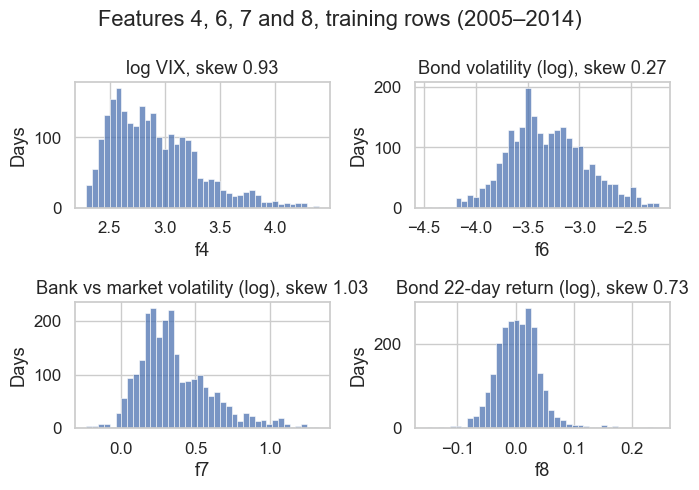

In [5]:
NAMES = {"f4": "log VIX",
         "f6": "Bond volatility (log)",
         "f7": "Bank vs market volatility (log)",
         "f8": "Bond 22-day return (log)"}

# Draw the histograms, one per feature
fig, axes = plt.subplots(2, 2, figsize=(7, 5))
for ax, col in zip(axes.flat, NAMES):
    sns.histplot(train[col], bins=40, ax=ax)
    ax.set_title(f"{NAMES[col]}, skew {train[col].skew():.2f}")
    ax.set_xlabel(col)
    ax.set_ylabel("Days")

fig.suptitle("Features 4, 6, 7 and 8, training rows (2005–2014)")

# Save histograms image under results folder
plt.tight_layout()
plt.savefig("results/figures/eda_hist_f4_f6_f7_f8.png", dpi=200)
plt.show()

### 2.3 Where the tails come from

For each feature with a clear right tail (f4, f7 and f8; f6 is roughly symmetric), we take its 20 highest training days and count how many fall in each year.

In [6]:
# Where do the right tails come from? Years of each feature's 20 highest days (training rows)
for col in ["f4", "f7", "f8"]:
    top = train.nlargest(20, col)
    print(col, top["date"].dt.year.value_counts().sort_index().to_dict())

f4 {2008: 20}
f7 {2008: 18, 2009: 2}
f8 {2008: 17, 2011: 3}


### 2.4 Result

Our conclusions so far are below:
- All four features are complete on the 2,452 training rows (no missing values). 
- f6 (bond volatility) is roughly symmetric (skew 0.27). The other three have a right tail: 
    - f7 (bank vs market volatility, skew 1.03) reaches 1.332.
    - f4 (log VIX, skew 0.93) reaches 4.393.
    - f8 (bond 22-day return, skew 0.73) is symmetric around 0 apart from a few large positive returns up to 0.245.
- The largest values of f4, f7, and f8 come mostly from 2008, so the tails come from a small number of stressed periods. f4, f6 and f7 are already logs, and the remaining skew is moderate, so we apply no further transform.


## 3. Correlations between all 10 features

This section checks whether some features carry the same information. That is the evidence for choosing Elastic Net over plain regression: if two features move together, plain regression can't tell which one deserves the credit and gives unstable coefficients, while Elastic Net keeps them together. High correlations in the heatmap show the problem that Elastic Net solves.

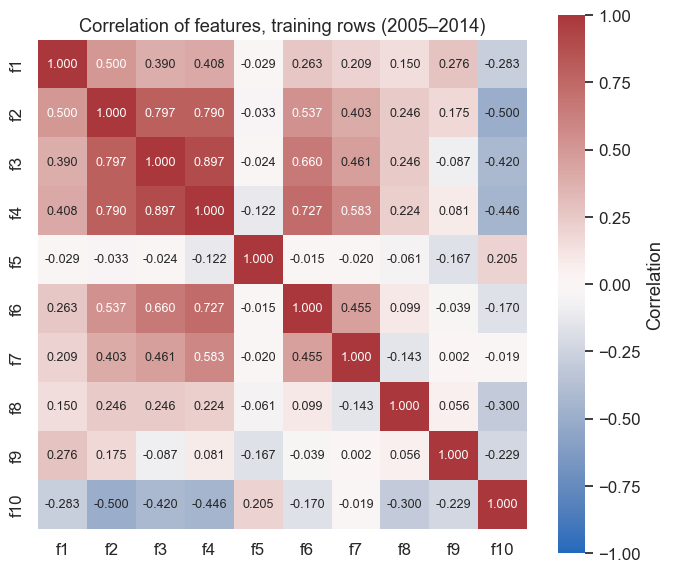

f3 vs f4 (log 22-day volatility vs log VIX): 0.897
f4  f3    0.897
f3  f2    0.797
f4  f2    0.790
f6  f4    0.727
dtype: float64


In [10]:
# Correlation of every pair of features of the training rows only.
corr = train[FEATURES].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="vlag",
            vmin=-1, vmax=1, center=0, square=True,
            annot_kws={"size": 9}, cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Correlation of features, training rows (2005–2014)")
plt.tight_layout()
plt.savefig("results/figures/eda_corr_heatmap.png", dpi=200)
plt.show()

# f3 is past volatility and the VIX is expected volatility, so we expect them to be correlated.
print(f"f3 vs f4 (log 22-day volatility vs log VIX): {corr.loc['f3', 'f4']:.3f}")

# Every other strongly correlated pair (|r| >= 0.7), strongest first
pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack()
print(pairs[pairs.abs() >= 0.7].sort_values(key=abs, ascending=False).round(3))


### 3.1 Result

Four pairs have |r| >= 0.7 on the training rows. Three form one group of SPY volatility measures: f4 (log VIX) with f3 (last 22 days), 0.897; f3 with f2 (last 5 days), 0.797; f4 with f2, 0.790. Past volatility and the volatility the market expects move closely together. The fourth pair is cross-asset: bond volatility (f6) with the VIX (f4), 0.727.

With correlated features, plain regression's coefficients become unstable, because it can't tell which feature deserves the credit. Elastic Net keeps correlated features together instead (the grouping effect; Zou & Hastie, 2005), so it is the better choice here.

Whether the extra features, such as f4 and f6, add information beyond HAR's features (f1–f3) is tested by comparing the model with HAR.

### 3.2 Decisions from the exploration

| Decision | Reason | Evidence (training rows) |
| --- | --- | --- |
| Use training rows only; create no test variable | The test years stay unseen until the single test run, so the final score honestly measures performance on unseen data | 2,452 rows, 2005-03-30 to 2014-12-23 |
| Report skew and median next to the mean | Skew shows whether a few extreme days stretch a feature; the median is a typical value those days can't pull | Skew: f4 0.925, f6 0.270, f7 1.030, f8 0.732 |
| No further transform of f4, f6–f8 | f4, f6 and f7 are already logs; the remaining skew is moderate, and the tails are real stressed periods the model must forecast | Of the 20 highest days: f4 20 in 2008; f7 18 in 2008, 2 in 2009; f8 17 in 2008, 3 in 2011 |
| Elastic Net instead of plain regression | Correlated features make plain regression's coefficients unstable; Elastic Net keeps correlated features together (grouping effect; Zou & Hastie, 2005) | Pearson r: f4–f3 0.897, f3–f2 0.797, f4–f2 0.790, f6–f4 0.727 |
| Pearson correlation on the log-scale features | It measures straight-line links between exactly the columns the linear model uses | As above |